# Combined M–c + Magnitude-Gap Recovery — Triaxial NFW Lensing

Simultaneously recovers the mass–concentration relation parameters
$(c_0, \alpha, \beta)$ **and** the magnitude-gap concentration slope $\gamma$
from un-stacked per-cluster $\Delta\Sigma$ profiles simulated with **triaxial NFW
shear** (random CDM-like axis ratios, isotropic line-of-sight orientations).

The combined parametric concentration is:

$$
\log_{10} c = \log_{10} c_0
  + \alpha\,(\log_{10} M - 14)
  + \beta\,\log_{10}\!\frac{1+z}{1+z_{\rm ref}}
  + \gamma\,\log_{10}\!\frac{\Delta m}{\Delta m_{\rm ref}}
$$

Truth concentrations are drawn from Dutton & Maccio (2014) with a non-zero $\gamma$
imprinted on the magnitude-gap distribution from the HOD satellite model.
The fitting model is **spherical NFW** — the test simultaneously probes triaxiality
bias and parameter degeneracies between the M–c shape and the fossil-cluster signal.

**Bias suppression**: `scatter_logc=0` and `poisson_richness=False` eliminate Jensen
and errors-in-variables biases, so any residual bias comes from triaxiality alone.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting import run_sampler_combined
from destacking.relations import c_DuttonMaccio
from destacking.model import _MC_M_PIVOT_LOG, _MC_Z_REF

from xlensing.sims import (
    make_simple_random_cat,
    apply_triaxial_NFW_shear_region,
    r_vir,
    project_ellipsoid,
)
from xlensing.data import metacal_cluster_lensing, signal
import ngmix

try:
    import corner
except ImportError:
    corner = None

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs): return it

Lookup tables loaded!


## Parameters

In [2]:
N_CLUSTERS   = 1000          # number of clusters
TRUE_GAMMA   = 0.2          # gamma [dex/dex]: d(log10 c)/d(log10(delta_m/delta_m_ref))
DELTA_M_REF  = 0.1        # reference magnitude gap [mag]
RADII        = np.logspace(-0.8, 0.8, 12)   # projected radii [Mpc]
SEED         = None

# ── Galaxy survey parameters ──
DENSITY         = 30
WIDTH_RAD       = 0.006     # field half-width [rad] ≈ ±20 arcmin
Z_SRC_RANGE     = (0.4, 1.5)
SHAPE_NOISE     = 0.27
NOISE_FLOOR_COV = 1e4       # [(M_sun/pc²)²]

# Bin limits
log_r  = np.log10(RADII)
dlog   = np.diff(log_r)[0]
edges  = np.logspace(log_r[0] - dlog/2, log_r[-1] + dlog/2, len(RADII) + 1)
bin_limits = np.column_stack([edges[:-1], edges[1:]])
N_BINS = len(RADII)

print(f'TRUE_GAMMA  = {TRUE_GAMMA}')
print(f'DELTA_M_REF = {DELTA_M_REF} mag')
print(f'M_pivot_log = {_MC_M_PIVOT_LOG},  z_ref = {_MC_Z_REF}')

TRUE_GAMMA  = 0.2
DELTA_M_REF = 0.1 mag
M_pivot_log = 14.0,  z_ref = 0.35


## 1 — Generate truth catalog

### Why `delta_m_gamma` cannot be used directly

`c_DuttonMaccio(z, M, c=c_param)` evaluates the DM14 formula as

$$\log_{10}c = a(z) + b(z)\,\log_{10}\!\frac{M}{c_{\rm param}\cdot10^{12}\,M_\odot}$$

so `c_param` **divides the pivot mass**, not the concentration.  Setting
`c_param = (\Delta m/\Delta m_{\rm ref})^\gamma` yields a log-space concentration
effect of only $|b(z)|\cdot\gamma \approx 0.10\,\gamma$, not $\gamma$ itself.

The forward model treats `gamma` as the full slope
$\mathrm{d}\log_{10}c\,/\,\mathrm{d}\log_{10}(\Delta m/\Delta m_{\rm ref})$.
To match this, the magnitude-gap scaling is applied as a **direct multiplicative
factor** on the base DM14 concentration:

$$\log_{10}c_{\rm truth} = \log_{10}c_{\rm DM}(z,M) + \gamma\,\log_{10}\!\frac{\Delta m}{\Delta m_{\rm ref}}$$

With this construction the OLS recovers $\gamma_{\rm OLS}\approx\gamma_{\rm true}$.

In [3]:
# Generate base concentrations from the DM relation (no gamma yet)
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range=(0.2, 0.6),
    logM_range=(13.5, 15.0),
    delta_m_gamma=0.0,   # gamma applied directly below
    scatter_logc=0.0,
    seed=SEED,
)

# Apply gamma as a direct log10(c) shift in log10(delta_m/delta_m_ref) space,
# matching the forward_model_combined parametrization exactly.
dm_s     = np.asarray(truth['delta_m'])
logdm_s  = np.log10(np.maximum(dm_s, 1e-6) / DELTA_M_REF)
truth['concentration'] = np.asarray(truth['concentration']) * 10.0 ** (TRUE_GAMMA * logdm_s)

# Extract truth parameters by OLS of log10(c) against model basis
logM_s  = np.log10(truth['M_halo'])
logc_s  = np.log10(truth['concentration'])
logz1_s = np.log10((1.0 + truth['z']) / (1.0 + _MC_Z_REF))

X = np.column_stack([
    np.ones(N_CLUSTERS),
    logM_s - _MC_M_PIVOT_LOG,
    logz1_s,
    logdm_s,              # gamma regressor is log10(delta_m / delta_m_ref)
])
coeffs, *_ = np.linalg.lstsq(X, logc_s, rcond=None)
logc0_true, alpha_true, beta_true, gamma_true = coeffs
c0_true = 10.0 ** logc0_true

print(f'Saved {N_CLUSTERS} clusters')
print(f'Truth:  c0={c0_true:.3f},  alpha={alpha_true:.4f},'
      f'  beta={beta_true:.4f},  gamma={gamma_true:.4f}')
print(f'(gamma_true should be ≈ TRUE_GAMMA = {TRUE_GAMMA})')
truth[:5]

Saved 10000 clusters
Truth:  c0=4.566,  alpha=-0.0909,  beta=-0.4681,  gamma=0.2001
(gamma_true should be ≈ TRUE_GAMMA = 0.2)


z,M_halo,concentration,M_BCG,L_BCG,L_brightest_sat,delta_m,N_sat
float64,float64,float64,float64,float64,float64,float64,int64
0.5095824194223852,69733617889138.18,5.221447085163699,183447184959.53546,1100160632.3000836,902479708.4137403,0.21504663594125478,9
0.3755513759008209,71741982738942.22,5.095140363972151,304162796505.0413,2380110008.425341,2064851821.4715126,0.15427034856744415,15
0.5434391679645529,36502295690818.37,4.717003310344044,145434663930.31442,708343522.0439507,644112644.8893018,0.10320525363561525,18
0.47894721162374554,32228032564632.03,4.57226464634493,512299975572.84015,4309948085.842696,4022969072.381495,0.07481336299679021,4
0.23767093915505982,41224933564783.42,6.280601958603039,300564488947.01953,2343099261.293935,1830107543.6858807,0.2682851898223754,13


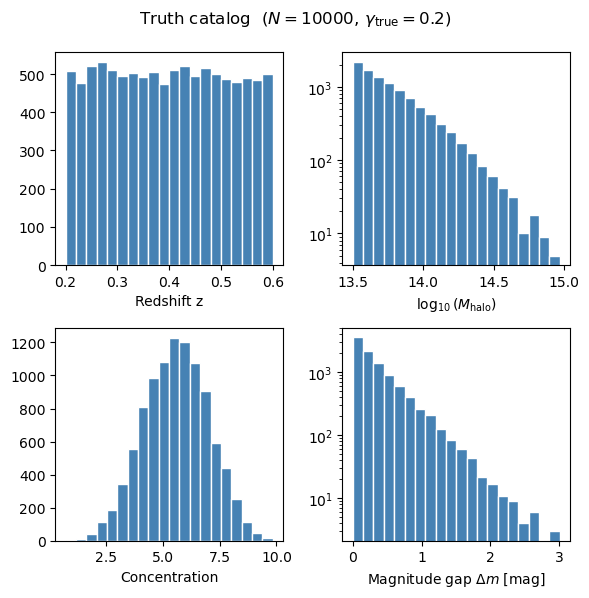

In [4]:
fig, axes = plt.subplots(2,2, figsize=(6,6))

axes[0,0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0,0].set_xlabel('Redshift z')

axes[0,1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[0,1].set_xlabel(r'$\log_{10}(M_{\rm halo})$')
axes[0,1].set_yscale('log')

axes[1,0].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[1,0].set_xlabel('Concentration')

axes[1,1].hist(truth['delta_m'], bins=20, color='steelblue', edgecolor='white')
axes[1,1].set_xlabel(r'Magnitude gap $\Delta m$ [mag]')
axes[1,1].set_yscale('log')

#for ax in axes: ax.set_ylabel('Count')
plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, $\gamma_{{\rm true}}={TRUE_GAMMA}$)',
    y=.99,
)
plt.tight_layout(); plt.show()

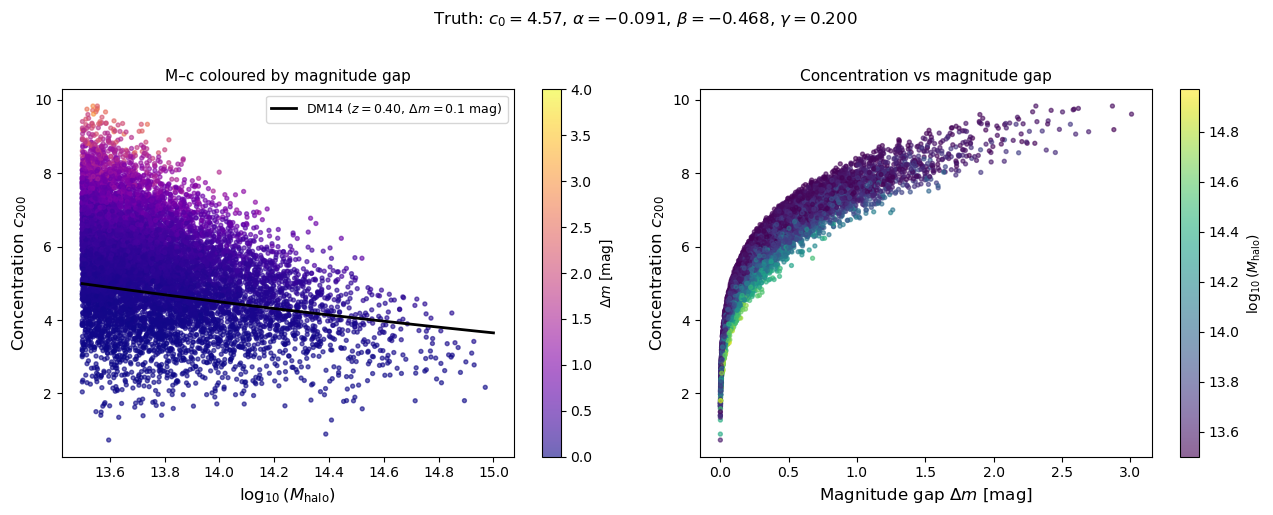

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# M–c scatter coloured by delta_m
ax = axes[0]
sc = ax.scatter(logM_s, truth['concentration'],
                c=truth['delta_m'], cmap='plasma', s=8, alpha=0.6,
                vmin=0, vmax=4, rasterized=True)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')
z_med  = float(np.median(truth['z']))
M_grid = np.logspace(13.5, 15.0, 200)
C_dm0  = c_DuttonMaccio(z_med * np.ones(200), M_grid, c=1.0)
ax.plot(np.log10(M_grid), C_dm0, 'k-', lw=2,
        label=rf'DM14 ($z={z_med:.2f}$, $\Delta m={DELTA_M_REF}$ mag)')
ax.set_xlabel(r'$\log_{10}(M_{\rm halo})$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title('M–c coloured by magnitude gap', fontsize=11)
ax.legend(fontsize=9)

# c vs delta_m coloured by log M
ax = axes[1]
sc2 = ax.scatter(truth['delta_m'], truth['concentration'],
                 c=logM_s, cmap='viridis', s=8, alpha=0.6, rasterized=True)
plt.colorbar(sc2, ax=ax, label=r'$\log_{10}(M_{\rm halo})$')
ax.set_xlabel(r'Magnitude gap $\Delta m$ [mag]', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(r'Concentration vs magnitude gap', fontsize=11)

plt.suptitle(
    rf'Truth: $c_0={c0_true:.2f}$, $\alpha={alpha_true:.3f}$, '
    rf'$\beta={beta_true:.3f}$, $\gamma={gamma_true:.3f}$',
    y=1.02, fontsize=12,
)
plt.tight_layout(); plt.show()

## 2 — Triaxial shapes

Projecting triaxial ellipsoids...
Projected q_min/q_maj: median=0.69, range [0.31, 1.00]


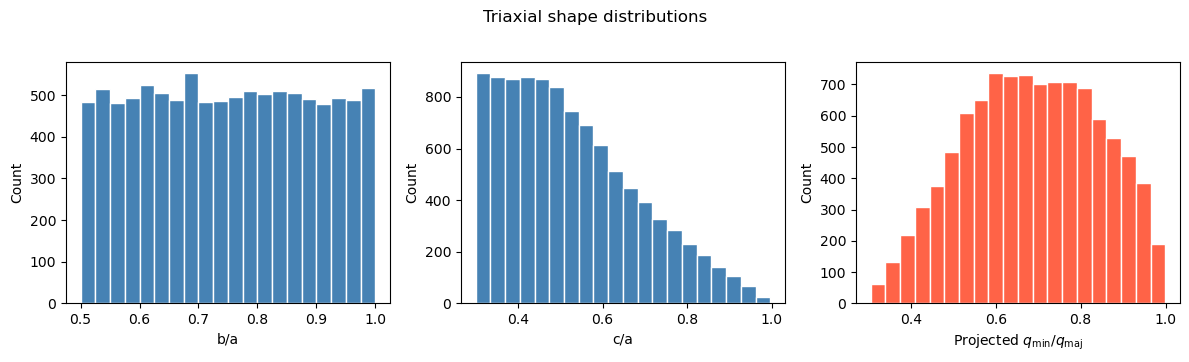

In [6]:
rng_tri = np.random.default_rng(SEED + 10)

r_vir_vals = np.array([
    r_vir(float(z), float(M))
    for z, M in zip(truth['z'], truth['M_halo'])
])

q_ba = rng_tri.uniform(0.5, 1.0, N_CLUSTERS)
q_ca = rng_tri.uniform(0.3, q_ba)

theta_los_arr = np.arccos(rng_tri.uniform(0.0, 1.0, N_CLUSTERS))
phi_los_arr   = rng_tri.uniform(0.0, 2 * np.pi, N_CLUSTERS)

print('Projecting triaxial ellipsoids...')
q_maj_arr = np.zeros(N_CLUSTERS)
q_min_arr = np.zeros(N_CLUSTERS)
pa_arr    = np.zeros(N_CLUSTERS)
for i in range(N_CLUSTERS):
    a = r_vir_vals[i]
    b, c = q_ba[i] * a, q_ca[i] * a
    q_maj_arr[i], q_min_arr[i], pa_arr[i] = project_ellipsoid(
        a, b, c, theta_los_arr[i], phi_los_arr[i]
    )

print(f'Projected q_min/q_maj: '
      f'median={np.median(q_min_arr/q_maj_arr):.2f}, '
      f'range [{(q_min_arr/q_maj_arr).min():.2f}, {(q_min_arr/q_maj_arr).max():.2f}]')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(q_ba, bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('b/a')
axes[1].hist(q_ca, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('c/a')
axes[2].hist(q_min_arr / q_maj_arr, bins=20, color='tomato', edgecolor='white')
axes[2].set_xlabel(r'Projected $q_{\rm min}/q_{\rm maj}$')
for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Triaxial shape distributions', y=1.02)
plt.tight_layout(); plt.show()

## 3 — Simulate triaxial NFW lensing

In [7]:
%%time
import multiprocess as mp
from scipy.interpolate import interp1d
import xlensing.cosmo as _xlc
import xlensing.sims as _xlsims

# ── DA spline patch ────────────────────────────────────────────────────────
_z_tab    = np.linspace(0.0, 3.0, 5000)
_chi_tab  = _xlc.cosmology.comoving_distance(_z_tab).value
_chi_of_z = interp1d(_z_tab, _chi_tab, kind='linear',
                     bounds_error=False, fill_value='extrapolate')

def _DA_fast(z1, z2):
    z2_a = np.atleast_1d(np.asarray(z2, dtype=float))
    res  = (_chi_of_z(z2_a) - float(_chi_of_z(float(z1)))) / (1.0 + z2_a)
    return float(res[0]) if np.ndim(z2) == 0 else res

_xlc.DA    = _DA_fast
_xlsims.DA = _DA_fast

# ── Background source field ────────────────────────────────────────────────
rng_base = np.random.default_rng(99)
base_cat = make_simple_random_cat(DENSITY, WIDTH_RAD, Z_SRC_RANGE,
                                  shape_noise=0.0, seed=0).T
N_GALS   = len(base_cat)

sizes  = rng_base.lognormal(mean=np.log(0.5), sigma=0.5, size=N_GALS)
R_RESP = np.clip(1.0 - (sizes / 1.5) ** 2, 0.05, 0.99)
base_cat[:, 5] = R_RESP
base_cat[:, 6] = 0.0
base_cat[:, 7] = 0.0
base_cat[:, 8] = R_RESP
print(f'Source field: {N_GALS} galaxies, half-width {WIDTH_RAD} rad')

# ── Per-cluster worker ─────────────────────────────────────────────────────
def _process_cluster(i):
    z_i = float(truth['z'][i])
    M_i = float(truth['M_halo'][i])
    c_i = float(truth['concentration'][i])
    a_i = r_vir_vals[i]

    rng_i  = np.random.default_rng(1000 + i)
    sp_i   = ngmix.priors.shape.GPriorBA(sigma=SHAPE_NOISE, rng=rng_i)
    e1, e2 = sp_i.sample2d(N_GALS)

    gal_i = base_cat.copy()
    gal_i[:, 3] = e1
    gal_i[:, 4] = e2

    mc_mask = gal_i[:, 2] > 1.1 * z_i + 0.2
    gal_mc  = gal_i[mc_mask]
    if len(gal_mc) < 20:
        return i, None, None

    cluster_arr = [0., 0., z_i, M_i, c_i,
                   a_i, q_ba[i] * a_i, q_ca[i] * a_i,
                   theta_los_arr[i], phi_los_arr[i]]
    gal_sheared = apply_triaxial_NFW_shear_region(cluster_arr, gal_mc)

    sources_mc = gal_sheared[:, [0, 1, 2, 3, 4, 9, 5, 6, 7, 8]]
    radius_mpc = WIDTH_RAD * _DA_fast(0, z_i)
    bg = metacal_cluster_lensing((0., 0., z_i), sources_mc.T, radius_mpc)
    if bg['Count'] < 20:
        return i, None, None

    stake = np.array([
        bg['Critical Density'], bg['Tangential Shear'], bg['Cross Shear'],
        bg['Weights'], bg['Radial Distance'], bg['Mult. Bias'],
    ])
    sig_t, _ = signal(stake, bin_limits)
    dv = np.nan_to_num(sig_t, nan=0.0)

    R      = bg['Radial Distance']
    in_bin = (R[:, None] > bin_limits[:, 0]) & (R[:, None] < bin_limits[:, 1])
    cov_d  = np.full(N_BINS, NOISE_FLOOR_COV)
    for b in range(N_BINS):
        m   = in_bin[:, b]
        n_b = m.sum()
        if n_b >= 5:
            cov_d[b] = (SHAPE_NOISE * bg['Critical Density'][m].mean()
                        / np.sqrt(n_b)) ** 2

    return i, dv, cov_d

# ── Output arrays ──────────────────────────────────────────────────────────
data_vectors = np.zeros((N_CLUSTERS, N_BINS))
cov_matrices = np.full((N_CLUSTERS, N_BINS, N_BINS), 0.0)
for i in range(N_CLUSTERS):
    np.fill_diagonal(cov_matrices[i], NOISE_FLOOR_COV)

# ── Parallel dispatch ──────────────────────────────────────────────────────
N_WORKERS = 15
with mp.Pool(N_WORKERS) as pool:
    for idx, dv, cov_d in tqdm(
        pool.imap(_process_cluster, range(N_CLUSTERS), chunksize=10),
        total=N_CLUSTERS, desc='Triaxial lensing',
    ):
        if dv is not None:
            data_vectors[idx] = dv
            np.fill_diagonal(cov_matrices[idx], cov_d)

non_empty = (np.diagonal(cov_matrices, axis1=1, axis2=2) < NOISE_FLOOR_COV).sum(1).mean()
print(f'\nNon-empty bins per cluster: {non_empty:.1f} / {N_BINS}')

Source field: 12764 galaxies, half-width 0.006 rad


Triaxial lensing:   0%|          | 0/10000 [00:00<?, ?it/s]

/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / 


Non-empty bins per cluster: 7.0 / 12
CPU times: user 3.03 s, sys: 993 ms, total: 4.02 s
Wall time: 1min 4s


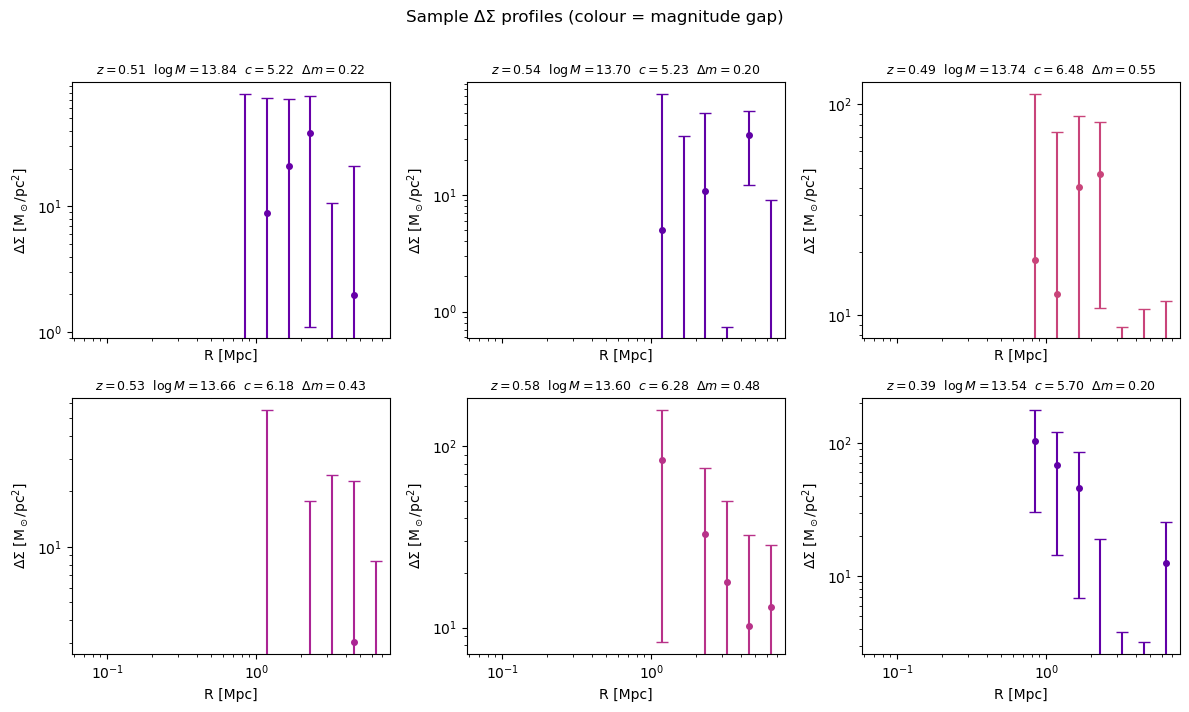

In [8]:
# Sanity check: six example profiles, coloured by delta_m
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

cmap_dm = plt.cm.plasma
dm_all  = np.asarray(truth['delta_m'])
vmin, vmax = 0.0, float(np.nanpercentile(dm_all, 95))

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    real = errs < np.sqrt(NOISE_FLOOR_COV)
    dm_i = float(truth['delta_m'][i])
    col  = cmap_dm((dm_i - vmin) / (vmax - vmin))
    ax.errorbar(RADII[real], data_vectors[i, real], yerr=errs[real],
                fmt='o', markersize=4, capsize=4, color=col)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(
        rf'$z={truth["z"][i]:.2f}$  '
        rf'$\log M={np.log10(truth["M_halo"][i]):.2f}$  '
        rf'$c={truth["concentration"][i]:.2f}$  '
        rf'$\Delta m={dm_i:.2f}$',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle('Sample ΔΣ profiles (colour = magnitude gap)', y=1.01)
plt.tight_layout(); plt.show()

## 4 — Cluster observable table

Richness from the deterministic McClintock+18 inversion of the true mass
(`poisson_richness=False`) — no Eddington bias.  The `delta_m` column from the
truth catalog is passed through for the gamma term in the forward model.

In [9]:
if SEED is not None:
    SEED1 = SEED + 1
else:
    SEED1 = None


cluster_obs, _, _ = make_test_data(
    truth, RADII,
    fractional_noise=0.2,
    poisson_richness=False,
    seed=SEED + 1,
)

print(f'Columns: {cluster_obs.colnames}')
print(f'Richness:  {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
print(f'delta_m:   {cluster_obs["delta_m"].min():.2f} – {cluster_obs["delta_m"].max():.2f}')
cluster_obs[:5]

Columns: ['z', 'Lambda', 'delta_m']
Richness:  6.6 – 97.6
delta_m:   0.00 – 3.01


z,Lambda,delta_m
float64,float64,float64
0.5095824194223852,14.523766242197075,0.21504663594125478
0.3755513759008209,13.86273452823525,0.15427034856744415
0.5434391679645529,9.139927882431731,0.10320525363561525
0.47894721162374554,8.108082498429829,0.07481336299679021
0.23767093915505982,8.326197325287637,0.2682851898223754


## 5 — Run the combined sampler

Fits $(c_0, \alpha, \beta, \gamma, \log M_{\rm norm})$ jointly against the triaxially-simulated
$\Delta\Sigma$ profiles.  The forward model is spherical NFW.

In [10]:
sampler = run_sampler_combined(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    c0_prior_loc=5.0,
    c0_prior_scale=5.0,
    alpha_prior_loc=0.0,
    alpha_prior_scale=0.5,
    beta_prior_loc=0.0,
    beta_prior_scale=1.0,
    gamma_range=(-1.0, 1.0),
    gamma_prior_sigma=0.5,
    delta_m_ref=DELTA_M_REF,
    fit_beta=True,
    n_live=400,
    pool=15,
    verbose=True,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 27     | 1        | 4        | 18060    | N/A    | 10090 | -780380.5


## 6 — Posterior analysis

In [11]:
points, log_w, log_l = sampler.posterior()
weights = np.exp(log_w - log_w.max())
weights /= weights.sum()

# Parameter order: c0, alpha, beta, gamma, log_M_norm
c0_s    = points[:, 0]
alpha_s = points[:, 1]
beta_s  = points[:, 2]
gamma_s = points[:, 3]
MN_s    = points[:, 4]

def wq(v, q):
    sorter = np.argsort(v)
    cs = np.cumsum(weights[sorter]) / weights.sum()
    return np.interp(q, cs, v[sorter])

truths_list = [c0_true, alpha_true, beta_true, gamma_true, 0.0]
names_list  = ['c0', 'alpha', 'beta', 'gamma', 'log_M_norm']
samples_list = [c0_s, alpha_s, beta_s, gamma_s, MN_s]

results = {}
print(f'{"param":<14} {"median":>10}  {"−1σ":>8}  {"+1σ":>8}  {"truth":>10}  {"bias":>8}')
print('-' * 65)
for name, samp, tv in zip(names_list, samples_list, truths_list):
    lo, md, hi = wq(samp, 0.16), wq(samp, 0.50), wq(samp, 0.84)
    sigma = (hi - lo) / 2
    bias  = (md - tv) / sigma if sigma > 0 else np.nan
    results[name] = (lo, md, hi, tv, bias)
    flag = '  ✓' if abs(bias) < 2 else '  BIASED'
    print(f'{name:<14} {md:>+10.4f}  {md-lo:>8.4f}  {hi-md:>8.4f}'
          f'  {tv:>+10.4f}  {bias:>+7.2f}σ{flag}')

param              median       −1σ       +1σ       truth      bias
-----------------------------------------------------------------
c0                +3.7743    0.0884    0.0887     +4.5661    -8.94σ  BIASED
alpha             -0.1041    0.0227    0.0221     -0.0909    -0.59σ  ✓
beta              -0.6083    0.1921    0.1919     -0.4681    -0.73σ  ✓
gamma             +0.2937    0.0151    0.0150     +0.2001    +6.22σ  BIASED
log_M_norm        -0.0124    0.0083    0.0085     +0.0000    -1.46σ  ✓


In [ ]:
if corner is not None:
    labels = [
        r'$c_0$',
        r'$\alpha$',
        r'$\beta$',
        r'$\gamma$',
        r'$\log M_{\rm norm}$',
    ]
    fig = corner.corner(
        points,
        weights=weights,
        labels=labels,
        truths=truths_list,
        truth_color='crimson',
        show_titles=True,
        title_fmt='.3f',
        smooth=1.0,
    )
    plt.suptitle(
        rf'Combined M–c + $\gamma$ recovery — triaxial lensing'
        rf'  ($N={N_CLUSTERS}$, $\gamma_{{\rm true}}={TRUE_GAMMA}$)',
        y=1.01, fontsize=13,
    )
    plt.savefig('figs/combined_posterior_triaxial.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Install corner for the triangle plot.')

## 7 — M–c recovery band at fixed magnitude gap

Shows posterior concentration bands at three representative $\Delta m$ values
against the DM14 truth curves.  The gamma term tilts the band relative to the
reference $\Delta m = \Delta m_{\rm ref}$ curve.

In [ ]:
M_grid  = np.logspace(13.5, 15.0, 200)
logM_g  = np.log10(M_grid)
z_med   = float(np.median(truth['z']))
logz1_g = np.log10((1 + z_med) / (1 + _MC_Z_REF))

dm_show    = [0.5, DELTA_M_REF, 2.0]
colors     = ['royalblue', 'steelblue', 'teal']
colors_tru = ['navy', 'darkblue', 'darkcyan']

# Draw 300 posterior samples for the bands
rng_plot = np.random.default_rng(0)
idx_band = rng_plot.choice(len(c0_s), size=300,
                           p=weights / weights.sum(), replace=True)

fig, ax = plt.subplots(figsize=(9, 6))

for dm_val, col, col_t in zip(dm_show, colors, colors_tru):
    log_dm_r = np.log10(max(dm_val, 1e-6) / DELTA_M_REF)
    label_dm = rf'$\Delta m = {dm_val:.1f}$ mag'

    # Posterior band
    C_band = np.array([
        10.0 ** (np.log10(c0_s[k])
                 + alpha_s[k] * (logM_g - _MC_M_PIVOT_LOG)
                 + beta_s[k]  * logz1_g
                 + gamma_s[k] * log_dm_r)
        for k in idx_band
    ])
    ax.fill_between(logM_g, C_band.min(0), C_band.max(0),
                    alpha=0.20, color=col)

    # Posterior median
    _, md_c, _, _, _ = results['c0']
    _, md_a, _, _, _ = results['alpha']
    _, md_b, _, _, _ = results['beta']
    _, md_g, _, _, _ = results['gamma']
    C_med = 10.0 ** (np.log10(md_c) + md_a * (logM_g - _MC_M_PIVOT_LOG)
                     + md_b * logz1_g + md_g * log_dm_r)
    ax.plot(logM_g, C_med, color=col, lw=2, label=f'Posterior median ({label_dm})')

    # Truth curve
    c_piv_true = 1.0 * (max(dm_val, 1e-6) / DELTA_M_REF) ** TRUE_GAMMA
    C_true = c_DuttonMaccio(z_med * np.ones(200), M_grid, c=c_piv_true)
    ax.plot(logM_g, C_true, '--', color=col_t, lw=1.5,
            label=f'DM14 truth ({label_dm})')

# Truth scatter
sc = ax.scatter(logM_s, truth['concentration'],
                c=truth['delta_m'], cmap='plasma', s=5, alpha=0.25,
                vmin=0, vmax=4, rasterized=True, zorder=0)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=13)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=13)
ax.set_title(
    rf'Combined M–c + $\gamma$ recovery from {N_CLUSTERS} triaxial clusters'
    '\n(spherical NFW forward model)',
    fontsize=12,
)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig('figs/combined_mc_recovery_triaxial.png', dpi=150)
plt.show()

## 8 — Gamma marginal posterior

In [ ]:
results['gamma']

In [ ]:
lo_g, md_g, hi_g, tv_g, bias_g = results['gamma']

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(gamma_s, weights=weights, bins=40, density=True,
        color='steelblue', alpha=0.65, edgecolor='white', label='Posterior')
ax.axvspan(lo_g, hi_g, alpha=0.20, color='steelblue',
           label=rf'68% CI  [{lo_g:.3f}, {hi_g:.3f}]')
ax.axvline(md_g,   color='steelblue', lw=1.5, ls='-',
           label=rf'Median $\hat{{\gamma}}$ = {md_g:.3f}')
ax.axvline(tv_g,   color='crimson',   lw=2.0, ls='--',
           label=rf'True $\gamma$ = {tv_g:.3f}')

ax.set_xlabel(r'$\gamma$  (magnitude-gap concentration slope)', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title(
    rf'$\gamma$ marginal — combined fit, {N_CLUSTERS} triaxial clusters'
    rf'  (bias = {bias_g:+.2f}σ)',
    fontsize=12,
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('figs/combined_gamma_marginal_triaxial.png', dpi=150)
plt.show()

print('\n--- Final summary ---')
for name, (lo, md, hi, tv, bias) in results.items():
    flag = 'OK' if abs(bias) < 2 else 'BIASED'
    print(f'  {name:<14}: {md:+.4f}  truth {tv:+.4f}  bias {bias:+.2f}σ  [{flag}]')